## Lec 9 - ML_Lab_7 - Transfer Learning with Residual Networks

For setup and data info, refer to our previous lab:
https://www.kaggle.com/code/emmanuelpintelas/image-based-ml-master-vision-classification?scriptVersionId=315710446

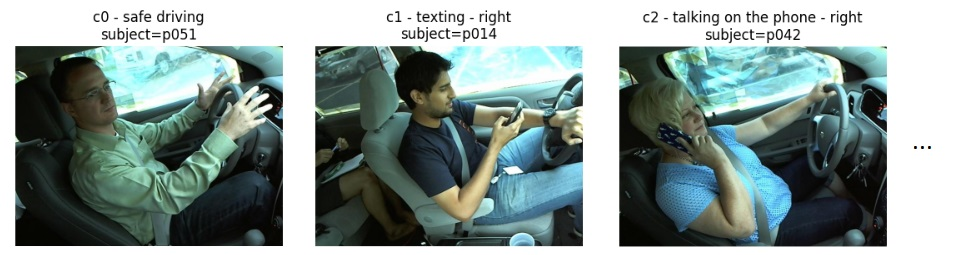


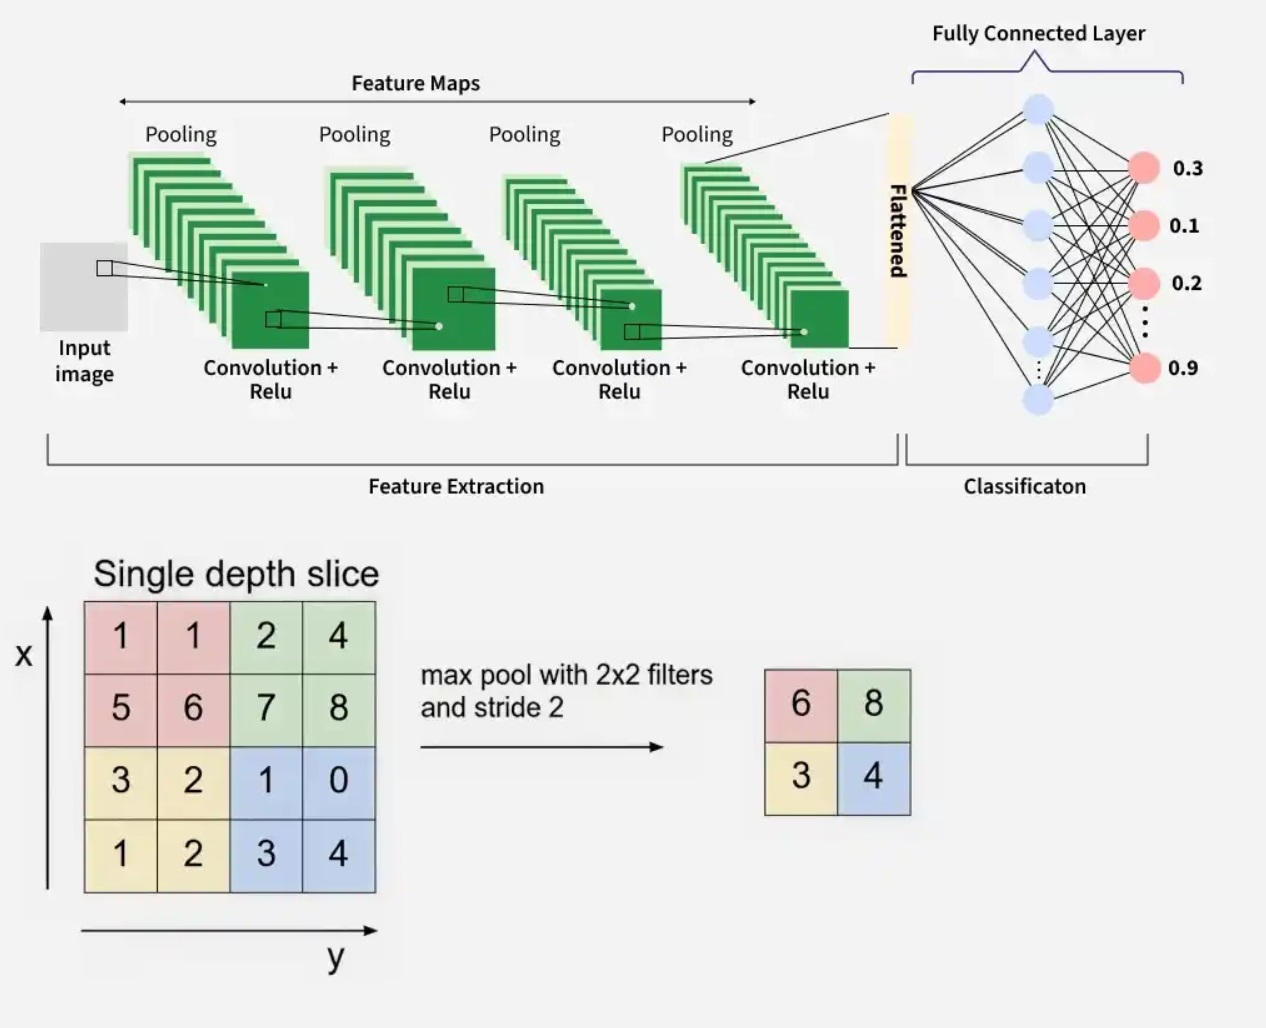


## We will work with Residual Networks (ResNet)

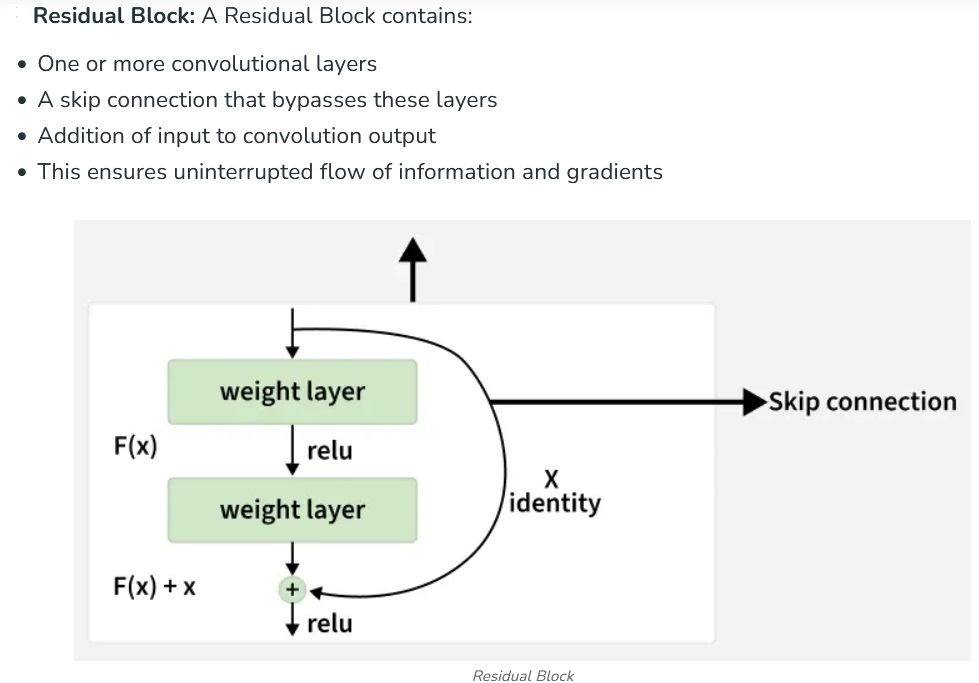

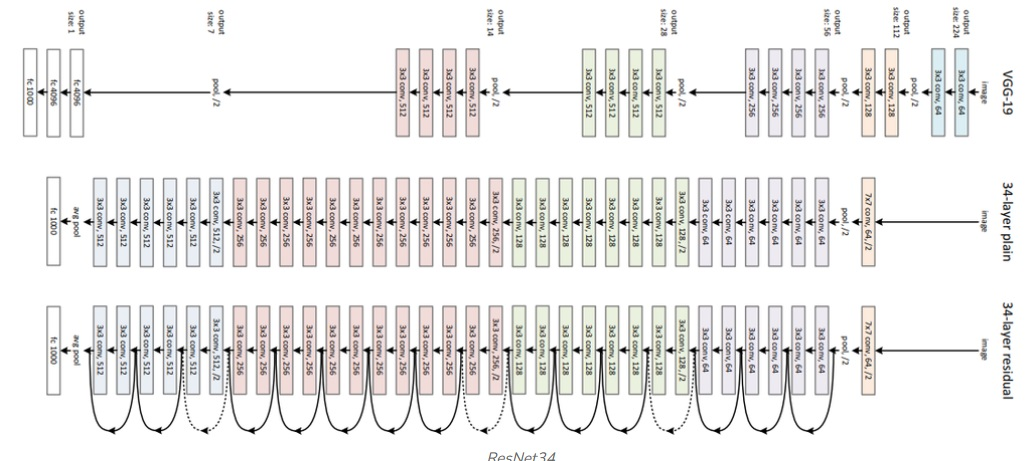

*images based on https://www.geeksforgeeks.org/machine-learning/introduction-convolution-neural-network/*

*https://www.geeksforgeeks.org/deep-learning/residual-networks-resnet-deep-learning/*

In [1]:
import os
import random
import time
import zipfile
import warnings
from pathlib import Path
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

Using device: cuda
GPU name: Tesla T4


In [2]:
# ---------------------------- MANDATORY (don't change this) -------------------------------------->
def seed_everything(seed=None):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(np.random.randint(1,10000))
# <---------------------------- MANDATORY (don't change this) --------------------------------------

In [3]:
# ---------------------------- MANDATORY (don't change this) -------------------------------------->
ROOT = "/kaggle/input/competitions/state-farm-distracted-driver-detection"
TRAIN_DIR = "/kaggle/input/competitions/state-farm-distracted-driver-detection/imgs/train"
csv_path = ROOT +'/'+ "driver_imgs_list.csv"
df = pd.read_csv(csv_path)

CLASS_NAMES = {
    "c0": "safe driving",
    "c1": "texting - right",
    "c2": "talking on the phone - right",
    "c3": "texting - left",
    "c4": "talking on the phone - left",
    "c5": "operating the radio",
    "c6": "drinking",
    "c7": "reaching behind",
    "c8": "hair and makeup",
    "c9": "talking to passenger",
}

CLASS_ORDER = [f"c{i}" for i in range(10)]
NUM_CLASSES = len(CLASS_ORDER)

df["class_name"] = df["classname"].map(CLASS_NAMES)

df["path"] = df.apply(lambda row: str(TRAIN_DIR +'/'+ row["classname"] +'/'+ row["img"]), axis=1)
# <---------------------------- MANDATORY (don't change this) --------------------------------------

In [4]:
df

,subject,classname,img,class_name,path
0,p002,c0,img_44733.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
1,p002,c0,img_72999.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
2,p002,c0,img_25094.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
3,p002,c0,img_69092.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
4,p002,c0,img_92629.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
...,...,...,...,...,...
22419,p081,c9,img_56936.jpg,talking to passenger,/kaggle/input/competitions/state-farm-distract...
22420,p081,c9,img_46218.jpg,talking to passenger,/kaggle/input/competitions/state-farm-distract...
22421,p081,c9,img_25946.jpg,talking to passenger,/kaggle/input/competitions/state-farm-distract...
22422,p081,c9,img_67850.jpg,talking to passenger,/kaggle/input/competitions/state-farm-distract...


In [5]:
# ---------------------------- MANDATORY (don't change this) -------------------------------------->
TEST_SUBJECTS = ["p014", "p021", "p061", "p082", "p050", "p051", "p072"]

test_df = df[df["subject"].isin(TEST_SUBJECTS)].reset_index(drop=True)
train_valid_df = df[~df["subject"].isin(TEST_SUBJECTS)].reset_index(drop=True)
# <---------------------------- MANDATORY (don't change this) --------------------------------------

In [6]:
# Group split αντί random: αποφεύγουμε data leakage από ίδιους οδηγούς σε train και val
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, valid_idx = next(gss.split(train_valid_df, groups=train_valid_df['subject']))
train_df = train_valid_df.iloc[train_idx].reset_index(drop=True)
valid_df = train_valid_df.iloc[valid_idx].reset_index(drop=True)

In [7]:
MAX_TRAIN_IMAGES_PER_CLASS = None
MAX_VALID_IMAGES_PER_CLASS = None
def sample_per_class(dataframe, max_per_class=None, seed=42):
    if max_per_class is None:
        return dataframe.sample(frac=1, random_state=seed).reset_index(drop=True)
    parts = []
    for class_id in CLASS_ORDER:
        class_df = dataframe[dataframe["classname"] == class_id]
        n = min(max_per_class, len(class_df))
        parts.append(class_df.sample(n=n, random_state=seed))
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

train_df_small = sample_per_class(train_df, MAX_TRAIN_IMAGES_PER_CLASS)
valid_df_small = sample_per_class(valid_df, MAX_VALID_IMAGES_PER_CLASS)

print("Training subset shape INIT:", train_df.shape)
print("Training subset shape:", train_df_small.shape)



Training subset shape INIT: (14070, 5)
Training subset shape: (14070, 5)


In [8]:
# Standard ImageNet input size and normalization values used by torchvision pretrained models.
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

valid_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


test_transform = valid_transform

In [9]:
class_to_idx = {class_id: i for i, class_id in enumerate(CLASS_ORDER)}
idx_to_class = {i: class_id for class_id, i in class_to_idx.items()}

class DriverImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        # Open image
        image = Image.open(row["path"]).convert("RGB")

        # Transform image
        if self.transform is not None:
            image = self.transform(image)

        # Convert class id to integer label
        label = class_to_idx[row["classname"]]

        return image, label


train_dataset = DriverImageDataset(train_df_small, transform=train_transform)
valid_dataset = DriverImageDataset(valid_df_small, transform=valid_transform)
test_dataset = DriverImageDataset(test_df, transform=test_transform)


print("Train dataset:", len(train_dataset))
print("Valid dataset:", len(valid_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 14070
Valid dataset: 3376
Test dataset: 4978


In [10]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


images, labels = next(iter(train_loader))

print("Batch image tensor shape:", images.shape)
print("Batch label tensor shape:", labels.shape)
print("Image tensor min:", images.min().item())
print("Image tensor mean:", images.mean().item())
print("Image tensor max:", images.max().item())

Batch image tensor shape: torch.Size([32, 3, 224, 224])
Batch label tensor shape: torch.Size([32])
Image tensor min: -2.1179039478302
Image tensor mean: -0.49047866463661194
Image tensor max: 2.640000104904175


## Transfer learning 

A NN trained from scratch starts with random weights.

At the beginning, it knows nothing about images.

A pretrained NN has already learned useful low-level and mid-level features.

E.g.:

- edges
- corners
- color blobs
- textures
- simple shapes
- object parts

These features may be useful even for a different problem.

---

### Three strategies

#### Strategy 1 — Feature extractor

Freeze the pretrained CNN body.  
Train only the final classifier layer.

This is fast and safer for small datasets.

#### Strategy 2 — Fine-tuning

Unfreeze some of the deeper layers.  
Train them with a smaller learning rate.

This can improve performance, but can also overfit more easily.

#### Strategy 3 — All-in training

Unfreeze everything.  
Train them with a smaller learning rate.

This can improve performance even more, but can also overfit even more easily.

---

Here we will use ResNet18 backbone.

ResNet18 is a CNN architecture.

The original ResNet18 classifier predicts 1000 ImageNet classes.

But our problem has 10 classes.

So we replace the final layer.


In [11]:
from torchvision import transforms, models

def create_resnet18_transfer_model(num_classes=10, freeze_features=True):
    """
    Create a ResNet18 model for our 10-class task.

    If pretrained weights loaded --> this is transfer learning.
    """
    # ---------------------------- MANDATORY (don't change this) -------------------------------------->
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)
    print("Loaded ImageNet-pretrained ResNet18 weights.")
    # <---------------------------- MANDATORY (don't change this) --------------------------------------

    if freeze_features:
        for param in model.parameters():
            param.requires_grad = False

    # Replace final classifier.
    # model.fc takes the final ResNet features and produces class logits.
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=0.30),
        nn.Linear(in_features, num_classes)
    )

    return model


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def count_total_parameters(model):
    return sum(p.numel() for p in model.parameters())


model = create_resnet18_transfer_model(
    num_classes=NUM_CLASSES,
    freeze_features=False
).to(device)

print(model)

print("\nTotal parameters:", f"{count_total_parameters(model):,}")
print("Trainable parameters:", f"{count_trainable_parameters(model):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


Loaded ImageNet-pretrained ResNet18 weights.
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_st

In [12]:
print("Trainable parameters by module:")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, tuple(param.shape))

Trainable parameters by module:
conv1.weight (64, 3, 7, 7)
bn1.weight (64,)
bn1.bias (64,)
layer1.0.conv1.weight (64, 64, 3, 3)
layer1.0.bn1.weight (64,)
layer1.0.bn1.bias (64,)
layer1.0.conv2.weight (64, 64, 3, 3)
layer1.0.bn2.weight (64,)
layer1.0.bn2.bias (64,)
layer1.1.conv1.weight (64, 64, 3, 3)
layer1.1.bn1.weight (64,)
layer1.1.bn1.bias (64,)
layer1.1.conv2.weight (64, 64, 3, 3)
layer1.1.bn2.weight (64,)
layer1.1.bn2.bias (64,)
layer2.0.conv1.weight (128, 64, 3, 3)
layer2.0.bn1.weight (128,)
layer2.0.bn1.bias (128,)
layer2.0.conv2.weight (128, 128, 3, 3)
layer2.0.bn2.weight (128,)
layer2.0.bn2.bias (128,)
layer2.0.downsample.0.weight (128, 64, 1, 1)
layer2.0.downsample.1.weight (128,)
layer2.0.downsample.1.bias (128,)
layer2.1.conv1.weight (128, 128, 3, 3)
layer2.1.bn1.weight (128,)
layer2.1.bn1.bias (128,)
layer2.1.conv2.weight (128, 128, 3, 3)
layer2.1.bn2.weight (128,)
layer2.1.bn2.bias (128,)
layer3.0.conv1.weight (256, 128, 3, 3)
layer3.0.bn1.weight (256,)
layer3.0.bn1.bias

In [13]:

def train_one_epoch(model, dataloader, loss_fn, optimizer, device, freeze_frozen_bn=True):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    progress_bar = tqdm(dataloader, desc="Training", leave=False)

    for images, labels in progress_bar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward pass.
        outputs = model(images)
        loss = loss_fn(outputs, labels)

        # Backward pass.
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        # Metrics.
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_examples += batch_size

    avg_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return avg_loss, accuracy


# ---------------------------- MANDATORY (don't change this) -------------------------------------->
def evaluate(model, dataloader, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    all_predictions = []
    all_labels = []
    all_probabilities = []

   
    progress_bar = tqdm(dataloader, desc="Evaluating", leave=False)

    with torch.no_grad():
        for images, labels in progress_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            probabilities = torch.softmax(outputs, dim=1)
            predictions = outputs.argmax(dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_examples += batch_size

            all_predictions.append(predictions.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            all_probabilities.append(probabilities.cpu().numpy())

    avg_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    all_predictions = np.concatenate(all_predictions)
    all_labels = np.concatenate(all_labels)
    all_probabilities = np.concatenate(all_probabilities)

    return avg_loss, accuracy, all_predictions, all_labels, all_probabilities
# <---------------------------- MANDATORY (don't change this) --------------------------------------

In [14]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4,
    weight_decay=1e-4
)
epochs = 5
for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
            model=model,
            dataloader=train_loader,
            loss_fn=loss_fn,
            optimizer=optimizer,
            device=device
        )

    valid_loss, valid_acc, valid_pred, valid_true, valid_probs = evaluate(
            model=model,
            dataloader=valid_loader,
            loss_fn=loss_fn,
            device=device
        )

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"train_loss={train_loss:.4f} | "
        f"train_acc={train_acc:.4f} | "
        f"valid_loss={valid_loss:.4f} | "
        f"valid_acc={valid_acc:.4f} | "
    )

Training:   0%|          | 0/440 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/106 [00:00<?, ?it/s]

Epoch 1/5 | train_loss=0.2522 | train_acc=0.9333 | valid_loss=0.6080 | valid_acc=0.8338 | 


Training:   0%|          | 0/440 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/106 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/106 [00:00<?, ?it/s]

Epoch 4/5 | train_loss=0.0183 | train_acc=0.9957 | valid_loss=0.7539 | valid_acc=0.7912 | 


Training:   0%|          | 0/440 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/106 [00:00<?, ?it/s]

Epoch 5/5 | train_loss=0.0085 | train_acc=0.9980 | valid_loss=0.4823 | valid_acc=0.8661 | 


In [15]:
# ---------------------------- MANDATORY (don't change this) -------------------------------------->
test_loss, test_acc, test_pred, test_true, test_probs = evaluate(
    model,
    test_loader,
    loss_fn,
    device
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
# <---------------------------- MANDATORY (don't change this) --------------------------------------

Evaluating:   0%|          | 0/156 [00:00<?, ?it/s]

Test loss: 0.3960
Test accuracy: 0.8998


# Homework 3
## Bonus: +1 (max)
### Deadline: 1 week (till 15/5/2026)
---
### With correct homeworks 1,2 and 3, it is: 
## +2.5 final grade bonus!

## Mini project

Καλείστε να φτιάξετε published notebook το οποίο θα περιέχει self-contained την υλοποίηση και τα σχόλια σας (αν χρειάζονται) για το παρακάτω task:

---
Τρέχτε το notebook αυτό και προβείτε σε ενέργειες ώστε το συνολικό μοντέλο σας βασισμένο στο ResNet18 backbone να φτάσει τουλάχιστον 85% testing accuracy. 

Notebooks που θα ξεπερνούν το **85% accuracy**, θα βαθμολογούνται με **+0.5 μονάδες.**

Notebooks που θα ξεπερνούν το **90% accuracy**, θα βαθμολογούνται **με επιπλέον +0.5 μονάδες ως extra bonus (+1 total max).**

Το test dataset **ΔΕΝ** πρέπει, σε καμία περίπτωση, να πειραχτεί ή να χρησιμοποιηθεί για οποιαδήποτε εξαγωγή πληροφορίας ώστε να βοηθηθεί το μοντέλο. Οποιαδήποτε προσπάθεια παραβίασης αυτού του κανόνα θα οδηγήσει σε ολικό μηδενισμό της βαθμολογίας του homework.

Επίσης, μέσα στο Notebook υπάρχουν μαρκαρισμένα σημεία κώδικα με "MANDATORY (don't change this)" τα οποία δεν πρέπει να αλλάξετε. 

Tο ελάχιστο output του notebook πρέπει να είναι ένα απλό print με του testing accuracy. πχ:

###### print(f"Test accuracy: {test_acc:.4f}")

---



##### Παραδίδεται εντός του deadline, mail με θέμα ML_HW3 - name - am
##### name: το όνομα σας, am: αριθμός μητρώου
##### στο mail: e.pintelas@unipi.gr
##### Στο body του mail απλά μου παρατίθεται το **link (public url)** με το published notebook σας (**όχι** combiled ipynb notebook).

##### Για να κάνετε **publish** το notebook σας, θα πατήσετε πάνω δεξία το "Save Version", το οποίο τρέχει το notebook (προϋποθέτει ότι το .ipynb αρχείο σας είναι απόλυτα μεταγλωτίσημο) και το αποθηκεύει ως μεταγλωτισμένο notebook στο προφίλ σας. Τέλος, πατώντας στο Share button, το κάνετε public για να μπορώ να ανοίξω το link, και μου το στέλνετε.

